In [2]:
%load_ext autoreload
%autoreload 2
%reload_ext autoreload

In [10]:
# Python imports 
import random 
from collections import defaultdict
from itertools import islice
from pprint import pp

# PyTorch imports 
import torch 
from torch.utils.data import DataLoader

# HRI_GNN imports
from hri_gnn.config.const import Configuration, SLOT_TABLE, MAX_SLOTS
from hri_gnn.utils.paths import get_output_path
from hri_gnn.datasets import raven_flat_collate
from hri_gnn.datasets import RavenDataset
from hri_gnn.models.cnn_encoder import RavenCnnEncoder
from hri_gnn.models.gnn_encoder import RavenGnnEncoder, RavenGnnModel, CandidateScorer , score_and_loss_for_batch
from hri_gnn.models import graph_builder as gb
from hri_gnn.losses import compute_candidate_loss

In [11]:
torch.manual_seed(92)
random.seed(92)

PERCENTAGE_LIMIT = 0.1
BATCH_SIZE = 10
active_configs = [Configuration.IN_DISTRIBUTE_FOUR_OUT_CENTER_SINGLE.value]
train_dataset_raven_100 = RavenDataset(
    dataset='raven-100',
    split='train',
    percentage_limit=PERCENTAGE_LIMIT,
    configs=active_configs
)

train_dataloader = DataLoader(
    dataset=train_dataset_raven_100,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=raven_flat_collate
)

In [12]:
# load the saved model 

output_path = get_output_path()

raven_encoder = RavenCnnEncoder()

raven_encoder.load_state_dict(torch.load(f=output_path/'models'/'raven_cnn_encoder_final.pth'))

<All keys matched successfully>

In [13]:
next(iter(raven_encoder.parameters())).device

device(type='cpu')

In [14]:
count = 0
for batch in train_dataloader:
    count+= 1
    conf_prblm_batch = torch.stack([batch[5],batch[6], batch[8]]).unique(dim=-1)
    numb_prblm= conf_prblm_batch.shape[1]
    zipped = zip(conf_prblm_batch[0].tolist(), conf_prblm_batch[1].tolist(), conf_prblm_batch[2].tolist())
    problem_ids = [(i,j,k) for i,j,k in zipped] 
    print(f"batch number: {count}, problems count: {numb_prblm}, (cnfg_id, prblm_id, btc_id): {problem_ids}")

print(f"dataset length: {len(train_dataset_raven_100)}")
print(f"dataloader length: {count}")

batch number: 1, problems count: 6, (cnfg_id, prblm_id, btc_id): [(4, 5, 4), (4, 44, 3), (4, 54, 2), (4, 60, 0), (4, 82, 1), (4, 92, 5)]
dataset length: 6
dataloader length: 1


In [15]:
flat_crops                = batch[0] # crops               ,shape: [xxx, 1, 80, 80]
flat_attributes           = batch[1] # attributes          ,shape: [xxx, 4]
flat_bboxes               = batch[2] # bbox                ,shape: [xxx, 4] 
flat_panel_indices        = batch[3] # panel indices       ,shape: [xxx]
flat_component_indices    = batch[4] # component indices   ,shape: [xxx]
flat_config_indices       = batch[5] # config indices      ,shape: [xxx]
flat_problem_indices      = batch[6] # problems indices    ,shape: [xxx]
flat_problem_targets      = batch[7] # problems targets    ,shape: [xxx]
flat_batch_indices        = batch[8] # batch indices       ,shape: [xxx]

# make predictions
raven_encoder.eval()
with torch.inference_mode():
    model_output = raven_encoder(flat_crops)
    
problems = gb.group_entities_by_problem(flat_config_indices,flat_problem_indices,flat_batch_indices)

In [16]:
key, indices = next(iter(problems.items()))

In [17]:
key, indices

((4, 60, 0),
 tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
         18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35,
         36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]))

In [21]:
hetero_data_dict, meta_dict = gb.build_hetero_data_batch(batch, raven_encoder, include_columns= True, candidate_ids=range(8,16), device= None)
pyg_batch, batched_layout_keys, keys_order = gb.build_pyg_batch(hetero_data_dict, meta_dict)

In [22]:
from hri_gnn.config.const import Configuration


print(f"number of graphs in the batch: {len(hetero_data_dict)}\n")
print(f"graph names: {hetero_data_dict.keys()}\n")
problem = '(4, 82, 1)'
candidate = 'c10'
graph = '(4, 82, 1)'+'_'+ 'c10'
hetero_data = hetero_data_dict[graph]

print(f"hetero_data entity x shape:\n{hetero_data['entity'].x.shape}\n")
print(f"hetero_data layout x shape:\n{hetero_data['layout'].x.shape}\n")

layout_contains_entity = hetero_data[('layout', 'contains', 'entity')]
entity_entity_intra_panel = hetero_data[('entity', 'intra_panel', 'entity')]
entity_entity_inter_panel = hetero_data[('entity', 'inter_panel_entity', 'entity')]
layout_layout_inter_panel = hetero_data[('layout', 'inter_panel_layout', 'layout')]
entity_belongs_to_layout = hetero_data[('entity', 'belongs_to', 'layout')]
print(f"hetero_data edges:\n")
print(f" - ('layout', 'contains', 'entity'): \n\t edge index shape:{layout_contains_entity.edge_index.shape}\n\t edge attr shape: {layout_contains_entity.edge_attr.shape}")
print(f" - ('entity', 'intra_panel', 'entity'): \n\t edge index: {entity_entity_intra_panel.edge_index.shape}\n\t edge attr shape: {entity_entity_intra_panel.edge_attr.shape}")
print(f" - ('entity', 'inter_panel_entity', 'entity'): \n\t edge index: {entity_entity_inter_panel.edge_index.shape}\n\t edge attr shape: {entity_entity_inter_panel.edge_attr.shape}")
print(f" - ('layout', 'inter_panel_layout', 'layout'): \n\t edge index: {layout_layout_inter_panel.edge_index.shape}\n\t edge attr shape: {layout_layout_inter_panel.edge_attr.shape}")
print(f" - ('entity', 'belongs_to', 'layout'): \n\t edge index :{entity_belongs_to_layout.edge_index.shape}\n\t edge attr shape: {entity_belongs_to_layout.edge_attr.shape}")



number of graphs in the batch: 48

graph names: dict_keys(['(4, 60, 0)_c8', '(4, 60, 0)_c9', '(4, 60, 0)_c10', '(4, 60, 0)_c11', '(4, 60, 0)_c12', '(4, 60, 0)_c13', '(4, 60, 0)_c14', '(4, 60, 0)_c15', '(4, 82, 1)_c8', '(4, 82, 1)_c9', '(4, 82, 1)_c10', '(4, 82, 1)_c11', '(4, 82, 1)_c12', '(4, 82, 1)_c13', '(4, 82, 1)_c14', '(4, 82, 1)_c15', '(4, 54, 2)_c8', '(4, 54, 2)_c9', '(4, 54, 2)_c10', '(4, 54, 2)_c11', '(4, 54, 2)_c12', '(4, 54, 2)_c13', '(4, 54, 2)_c14', '(4, 54, 2)_c15', '(4, 44, 3)_c8', '(4, 44, 3)_c9', '(4, 44, 3)_c10', '(4, 44, 3)_c11', '(4, 44, 3)_c12', '(4, 44, 3)_c13', '(4, 44, 3)_c14', '(4, 44, 3)_c15', '(4, 5, 4)_c8', '(4, 5, 4)_c9', '(4, 5, 4)_c10', '(4, 5, 4)_c11', '(4, 5, 4)_c12', '(4, 5, 4)_c13', '(4, 5, 4)_c14', '(4, 5, 4)_c15', '(4, 92, 5)_c8', '(4, 92, 5)_c9', '(4, 92, 5)_c10', '(4, 92, 5)_c11', '(4, 92, 5)_c12', '(4, 92, 5)_c13', '(4, 92, 5)_c14', '(4, 92, 5)_c15'])

hetero_data entity x shape:
torch.Size([36, 86])

hetero_data layout x shape:
torch.Size([18, 9

In [13]:
# Active edges 
layout_layout_edges = [
         ('entity', 'intra_panel', 'entity'), 
         ('entity', 'inter_panel_entity', 'entity'),
         ('layout', 'inter_panel_layout', 'layout'),
         ('entity', 'belongs_to', 'layout'),
         ('layout', 'contains', 'entity')
    ]

# Input nodes dimenstion , here we use unified batch vector `batch['node_type'].x` (concatenation of all the problems in the batch)
in_dims = {'entity': pyg_batch['entity'].x.shape[1] , 'layout': pyg_batch['layout'].x.shape[1]}

# instantiation of the GNN encoder, with  iput the batch vector `batch['node_type'].x` dimension, hidden dimension 64,  3 layers and only layout <-> layout active edges
gnn = RavenGnnEncoder(in_dims, hidden_dim=64, num_layers=3, active_edge_types=None)

# The actual repspresentaion of the nodes  (we use the batch vector `batch['node_type'].x` and for this example only the layout nodes)
x_dict = {'entity': pyg_batch['entity'].x , 'layout': pyg_batch['layout'].x}

# Edges dictionnaries (indexes and attributes) (we use the batch vector `batch[('egde_type')].edge_index` & `batch[('egde_type')].edge_attr` and for this specific example only layout <-> layout edges, see active_edge_types above)
edge_index_dict = {edge_type : pyg_batch[edge_type].edge_index for edge_type in layout_layout_edges}
edge_attr_dict = {edge_type : pyg_batch[edge_type].edge_attr for edge_type in layout_layout_edges}

# Forward 'MESSAGE PASSING' + Updating representation `batch['node_type'].x` (nodes attr only but using edges attr, see `GINEConv`)
gnn_out = gnn(x_dict, edge_index_dict, edge_attr_dict)

print(f"Gnn Encoder output:\n")
print(f"Layout representations:\n{gnn_out['layout']} , with shape {gnn_out['layout'].shape}")
print(f"Batch vector , Layout representations:\n{pyg_batch['layout'].batch} , with shape {pyg_batch['layout'].batch.shape}")



Gnn Encoder output:

Layout representations:
tensor([[ 0.7568,  1.4977,  0.4847,  ..., -0.2219, -0.0760,  0.0525],
        [ 0.8371,  1.5769,  0.9775,  ..., -0.5837,  0.0963, -0.1356],
        [ 1.7950,  1.0157,  1.0961,  ..., -0.8442,  0.0091, -0.6173],
        ...,
        [-0.3773,  1.2817, -0.3521,  ..., -1.3709,  0.5686,  0.1034],
        [ 1.8484,  1.1198,  0.8519,  ..., -0.3646,  0.1261, -0.5888],
        [-0.3535,  1.6417,  0.0382,  ..., -1.3356,  1.0055, -0.1839]],
       grad_fn=<NativeLayerNormBackward0>) , with shape torch.Size([864, 64])
Batch vector , Layout representations:
tensor([ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
         2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,
         3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,  3,
         4,  4,  4,  4,  4,  4,  4,  4,  4,  4,  4,  4,  4,  4,  4,  4,  4,  4,
    

***score_and_loss_for_batch***

In [32]:
h_layout = gnn_out['layout']
layout_batch_vector = pyg_batch['layout'].batch
y_batch = pyg_batch.y
candidate_ids = range(8,16)
scorer = CandidateScorer(hidden_dim=64)
n_problems = len(keys_order) // len(candidate_ids)
scores_per_problem, losses_per_problem, mean_loss = score_and_loss_for_batch(h_layout, layout_batch_vector, batched_layout_keys, y_batch, scorer, candidate_ids, n_problems)
#scores_per_problem[0]
losses_per_problem
#mean_loss

[tensor(2.0558, grad_fn=<NllLossBackward0>),
 tensor(2.1088, grad_fn=<NllLossBackward0>),
 tensor(2.0954, grad_fn=<NllLossBackward0>),
 tensor(2.0699, grad_fn=<NllLossBackward0>),
 tensor(2.1193, grad_fn=<NllLossBackward0>),
 tensor(2.0696, grad_fn=<NllLossBackward0>)]

***RavenGnnModel***

In [23]:
# in_dims = {'layout': pyg_batch['layout'].x.shape[1]}

raven_gnn_model = RavenGnnModel(in_dims=in_dims, hidden_dim=64, num_layers=3) # since active_edge_types = None -> all edge type are activated

scores_per_problem, losses_per_problem, mean_loss = raven_gnn_model(pyg_batch, batched_layout_keys, n_problems)

scores_per_problem, losses_per_problem, mean_loss

([tensor([-3.4539, -3.9598, -3.7368, -3.5318, -3.7378, -3.7384, -3.4754, -3.7398],
         grad_fn=<CatBackward0>),
  tensor([-4.0983, -3.8774, -3.8774, -3.8777, -3.8766, -3.8772, -3.8764, -4.2520],
         grad_fn=<CatBackward0>),
  tensor([-2.8146, -2.5672, -2.5673, -2.7914, -2.5673, -2.2137, -2.6065, -2.2595],
         grad_fn=<CatBackward0>),
  tensor([-2.9301, -2.9334, -1.6213, -2.8653, -2.8978, -2.9279, -2.8398, -2.8969],
         grad_fn=<CatBackward0>),
  tensor([-4.0019, -4.8191, -4.0011, -4.0041, -3.9298, -4.0012, -4.3109, -3.9916],
         grad_fn=<CatBackward0>),
  tensor([-3.5357, -3.2243, -3.5357, -4.0235, -3.2923, -3.5357, -3.5357, -3.5357],
         grad_fn=<CatBackward0>),
  tensor([ 4.0217,  4.0383,  2.6520,  2.6573,  2.6414,  5.1983,  3.7189, -2.8907],
         grad_fn=<CatBackward0>),
  tensor([-2.3436, -2.3530, -2.3536, -2.3141, -2.2932, -2.3486, -2.2899, -2.5843],
         grad_fn=<CatBackward0>),
  tensor([-7.5116, -2.5976, -3.9084, -5.9616, -3.0964, -5.1673, 

In [23]:
%load_ext autoreload
%autoreload 2
%reload_ext autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [24]:
# Python imports 
import random 
from collections import defaultdict
from itertools import islice
from pprint import pp
import json

# PyTorch imports 
import torch
import torch.nn as nn 
from torch.utils.data import DataLoader

# matplotlib imports
import matplotlib.pyplot as plt 

# HRI_GNN imports
from hri_gnn.config.const import Configuration, SLOT_TABLE, MAX_SLOTS, GRAPH_NODE_TYPES, GRAPH_EDGE_TYPES
from hri_gnn.utils import paths
from hri_gnn.datasets import raven_flat_collate
from hri_gnn.datasets import RavenDataset
from hri_gnn.models.cnn_encoder import RavenCnnEncoder
from hri_gnn.models.gnn_encoder import RavenGnnModel  #,RavenGnnEncoder , CandidateScorer , score_and_loss_for_batch
#from hri_gnn.models import graph_builder as gb
#from hri_gnn.losses import compute_candidate_loss
from hri_gnn.trainers import GnnTrainer

In [25]:
# load the saved model 

output_path = paths.get_output_path()

raven_encoder = RavenCnnEncoder()

raven_encoder.load_state_dict(torch.load(f=output_path/'models'/'raven_cnn_encoder_final.pth'))

<All keys matched successfully>

In [4]:
from hri_gnn.config.const import SPLITS
torch.manual_seed(92)
random.seed(92)

DATASET = 'raven-100'
PERCENTAGE_LIMIT = 0.1
BATCH_SIZE = 10

active_configs = [Configuration.CENTER_SINGLE.value]

datatsets_dict = {}
dataloaders_dict = {}

for config in Configuration.all()[:1]:
    for split in SPLITS:
        datatsets_dict[f"{config}_{split}"] = RavenDataset(dataset=DATASET,
                                              split=split,
                                              percentage_limit=PERCENTAGE_LIMIT,
                                              configs=[config])
        dataloaders_dict[f"{config}_{split}"] = DataLoader(
                                                dataset=datatsets_dict[f"{config}_{split}"],
                                                batch_size=BATCH_SIZE,
                                                shuffle= split == 'train',
                                                collate_fn=raven_flat_collate)

In [6]:
for config in Configuration.all()[:1]:
    print("="*60)
    for split in SPLITS:
        print(f"{config}_{split}: \t\t {len(datatsets_dict[f"{config}_{split}"])}")

center_single_train: 		 6
center_single_test: 		 2
center_single_val: 		 2


***GnnTrainer***

In [24]:
output_path = paths.get_output_path()
paths.output_paths(output_path)

gnn_model = RavenGnnModel(GRAPH_NODE_TYPES, hidden_dim=32, num_layers=3).to("cuda")
optimizer = torch.optim.Adam(gnn_model.parameters(), lr=1e-3)

# homogeniuos edges
option_A = [ ('entity', 'intra_panel', 'entity'),('entity', 'inter_panel_entity', 'entity'),('layout', 'inter_panel_layout', 'layout')]
# layout edges only
option_B = [ ('layout', 'inter_panel_layout', 'layout')]
# inter panels only 
option_C = [ ('entity', 'inter_panel_entity', 'entity'), ('layout', 'inter_panel_layout', 'layout')]
# entity edges only
option_D = [ ('entity', 'intra_panel', 'entity'),('entity', 'inter_panel_entity', 'entity')]

train_only = False
active_edge_types = None # all edges are activated
include_columns = True 
epochs = 10

history_dict = {}
for config in Configuration.all()[:1]:
    print(f"Training {config}....")

    # 1. Instantiate the GNN model (fresh instace for each config)
    gnn_trainer = GnnTrainer(gnn_model, raven_encoder, optimizer, metrics=None, node_types= None, 
                             active_edge_types= active_edge_types, 
                             include_columns=include_columns, device="cuda", output_path= None)
    # 2. Train the GNN model
    history_dict[config] = gnn_trainer.fit(dataloaders_dict[f"{config}_train"] , 
                                           dataloaders_dict[f"{config}_test"], 
                                           epochs=epochs, 
                                           max_grad_norm=None, 
                                           checkpoint_name_prefix = config,
                                           check_frequency=0,
                                           save_final_version= False,
                                           verbose=True, 
                                           train_only= train_only)
    # 3. Saving the training history
    # history_path = output_path/"history"/"gnn"/f"training_history_{config}.json"
    # with open(history_path, 'w') as f:
    #     json.dump(history_dict[config], f, indent=2)
    # print(f"\n[OK] Training history {config} saved : {history_path}")

    print("="*80)

Training center_single....


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 1/10 - Train Loss: 2.0477 | Train Acc: 0.1045 | Test Loss: 2.0159 | Test Acc: 0.1266
Epoch 2/10 - Train Loss: 1.9983 | Train Acc: 0.1300 | Test Loss: 1.9746 | Test Acc: 0.1533
Epoch 3/10 - Train Loss: 1.9657 | Train Acc: 0.1555 | Test Loss: 1.9557 | Test Acc: 0.1628
Epoch 4/10 - Train Loss: 1.9351 | Train Acc: 0.1714 | Test Loss: 1.9548 | Test Acc: 0.1845
Epoch 5/10 - Train Loss: 1.9255 | Train Acc: 0.1767 | Test Loss: 1.9345 | Test Acc: 0.1724
Epoch 6/10 - Train Loss: 1.9023 | Train Acc: 0.1893 | Test Loss: 1.9152 | Test Acc: 0.1927
Epoch 7/10 - Train Loss: 1.8785 | Train Acc: 0.2009 | Test Loss: 1.9244 | Test Acc: 0.1826
Epoch 8/10 - Train Loss: 1.8674 | Train Acc: 0.2037 | Test Loss: 1.8867 | Test Acc: 0.2074
Epoch 9/10 - Train Loss: 1.8460 | Train Acc: 0.2211 | Test Loss: 1.8804 | Test Acc: 0.2061
Epoch 10/10 - Train Loss: 1.8139 | Train Acc: 0.2326 | Test Loss: 1.8452 | Test Acc: 0.2277

Training finished!....
- Train (Test) number of problems: [4708] ([1572])
- Train (Test)

In [ ]:
history_dict


In [ ]:
# read json history_dict 
#output_path = paths.get_output_path()
train_only=False
for config in Configuration.all()[:1]:
    # history_dict_path = output_path /"history"/"gnn"/f"training_history_{config}.json"
    # with open(history_dict_path, 'r') as json_file:
    #     history_dict = json.load(json_file)
        # print(history_dict)
    cfg_history_dict = history_dict[config]
    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12,10))
    subtitle = f"{config} Loss and Accuracy \n"
    subtitle +=f"NB problems Train (Test): {cfg_history_dict["train_number_of_problems"]} ({cfg_history_dict["test_number_of_problems"]})\n"
    subtitle +=f"NB Entity Train (Test): {cfg_history_dict["train_entity"]} ({cfg_history_dict["test_entity"]})\n" 
    subtitle +=f"NB Layout Train (Test): {cfg_history_dict["train_layout"]} ({cfg_history_dict["test_layout"]})" 

    fig.suptitle(subtitle, fontsize=11)
    axes[0].plot(range(epochs), cfg_history_dict['train_loss'] , color='blue', linewidth=2, label='train loss')
    if not train_only:
        axes[0].plot(range(epochs), cfg_history_dict['test_loss'] , color='red', linewidth=2, label='test loss')
    axes[0].set_title(f'Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(True, alpha=0.2, color='#555')
    axes[1].plot(range(epochs), cfg_history_dict['train_accuracy'],color="black",linewidth=2, label=f'train accuracy')
    if not train_only:
        axes[1].plot(range(epochs), cfg_history_dict['test_accuracy'],color="green",linewidth=2, label=f'test accuracy')
    axes[1].set_title(f'accuracy')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('accuracy')
    axes[1].legend()
    axes[1].grid(True, alpha=0.2, color='#555')

    # gnn_curves_path = output_path/"metric_curves"/"gnn"/f"{config}_loss_accuracy.png"
    # plt.savefig(gnn_curves_path)
    # print(f"\n[OK] {config} curves saved to {gnn_curves_path}")



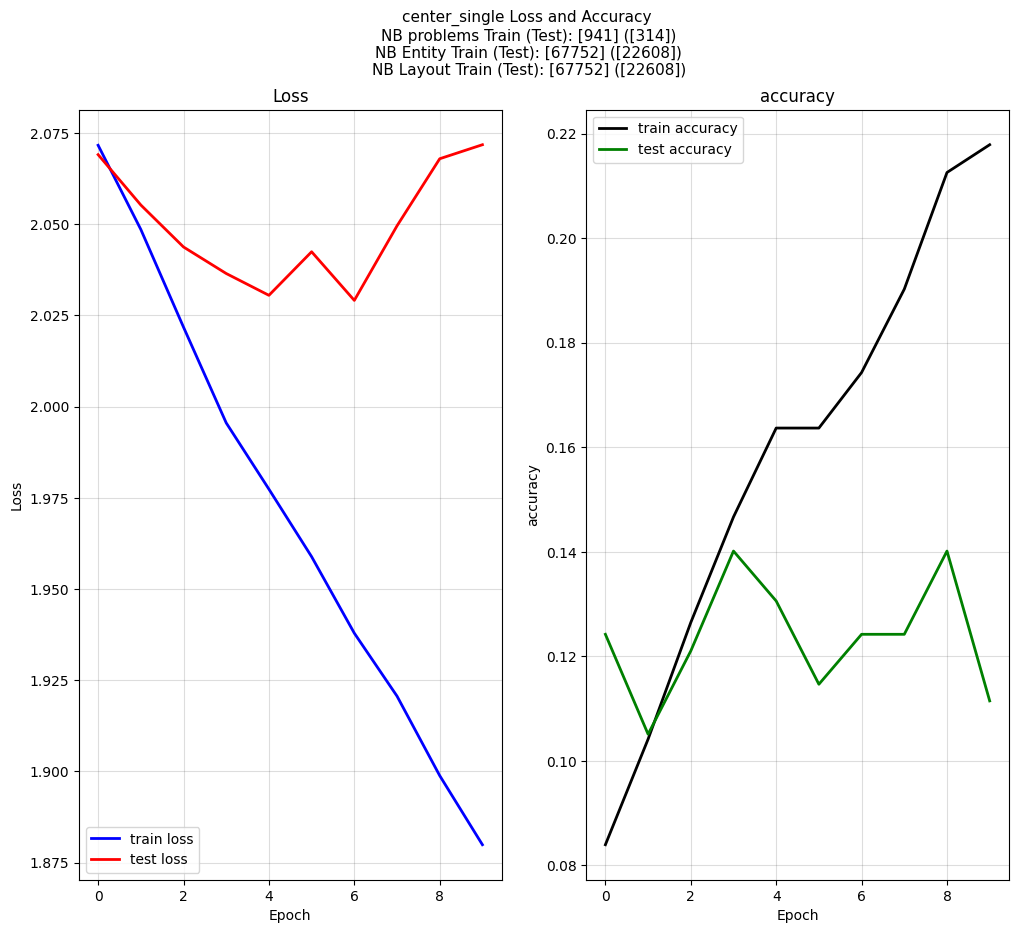

In [ ]:
# read json history_dict 
output_path = paths.get_output_path()
train_only=False
for config in Configuration.all()[:1]:
    # history_dict_path = output_path /"history"/"gnn"/f"training_history_{config}.json"
    # with open(history_dict_path, 'r') as json_file:
    #     history_dict = json.load(json_file)
        # print(history_dict)
    cfg_history_dict = history_dict[config]
    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12,10))
    subtitle = f"{config} Loss and Accuracy \n"
    subtitle +=f"NB problems Train (Test): {cfg_history_dict["train_number_of_problems"]} ({cfg_history_dict["test_number_of_problems"]})\n"
    subtitle +=f"NB Entity Train (Test): {cfg_history_dict["train_entity"]} ({cfg_history_dict["test_entity"]})\n" 
    subtitle +=f"NB Layout Train (Test): {cfg_history_dict["train_layout"]} ({cfg_history_dict["test_layout"]})" 

    fig.suptitle(subtitle, fontsize=11)
    axes[0].plot(range(epochs), cfg_history_dict['train_loss'] , color='blue', linewidth=2, label='train loss')
    if not train_only:
        axes[0].plot(range(epochs), cfg_history_dict['test_loss'] , color='red', linewidth=2, label='test loss')
    axes[0].set_title(f'Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(True, alpha=0.2, color='#555')
    axes[1].plot(range(epochs), cfg_history_dict['train_accuracy'],color="black",linewidth=2, label=f'train accuracy')
    if not train_only:
        axes[1].plot(range(epochs), cfg_history_dict['test_accuracy'],color="green",linewidth=2, label=f'test accuracy')
    axes[1].set_title(f'accuracy')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('accuracy')
    axes[1].legend()
    axes[1].grid(True, alpha=0.2, color='#555')

    # gnn_curves_path = output_path/"metric_curves"/"gnn"/f"{config}_loss_accuracy.png"
    # plt.savefig(gnn_curves_path)
    # print(f"\n[OK] {config} curves saved to {gnn_curves_path}")



In [1]:
%load_ext autoreload
%autoreload 2
%reload_ext autoreload

In [1]:
# Python imports 
import random 
from collections import defaultdict
from itertools import islice
from pprint import pp
import json

# PyTorch imports 
import torch
import torch.nn as nn 
from torch.utils.data import DataLoader

# matplotlib imports
import matplotlib.pyplot as plt 

# HRI_GNN imports
from hri_gnn.config.const import Configuration, SLOT_TABLE, MAX_SLOTS, GRAPH_NODE_TYPES, GRAPH_EDGE_TYPES
from hri_gnn.utils import paths
from hri_gnn.datasets import raven_flat_collate
from hri_gnn.datasets import RavenDataset
from hri_gnn.models.cnn_encoder import RavenCnnEncoder
from hri_gnn.models.gnn_encoder import RavenGnnModel 
from hri_gnn.trainers import GnnTrainer

In [4]:
from hri_gnn.datasets.precomputed import PrecomputedRavenDataset, precomputed_collate
from hri_gnn.config.const import SPLITS
torch.manual_seed(92)
random.seed(92)

DATASET = 'raven-20000'
PERCENTAGE_LIMIT = 0.5
BATCH_SIZE = 128

active_configs = [Configuration.CENTER_SINGLE.value]

datatsets_dict = {}
dataloaders_dict = {}

for config in active_configs:
    for split in SPLITS:
        datatsets_dict[f"{config}_{split}"] = PrecomputedRavenDataset(dataset=DATASET,
                                              split=split,
                                              percentage_limit=PERCENTAGE_LIMIT,
                                              configs=[config])
        dataloaders_dict[f"{config}_{split}"] = DataLoader(
                                                dataset=datatsets_dict[f"{config}_{split}"],
                                                batch_size=BATCH_SIZE,
                                                shuffle= split == 'train',
                                                collate_fn=precomputed_collate,
                                                num_workers=4)

In [3]:
from hri_gnn.datasets.precomputed import PrecomputedRavenDataset, precomputed_collate
from hri_gnn.config.const import SPLITS
torch.manual_seed(92)
random.seed(92)

DATASET = 'raven-100'
PERCENTAGE_LIMIT = 1
BATCH_SIZE = 128

# active_configs = [Configuration.CENTER_SINGLE.value]

datatsets_dict = {}
dataloaders_dict = {}

# for config in active_configs:
for split in SPLITS:
    datatsets_dict[f"{split}"] = PrecomputedRavenDataset(dataset=DATASET,
                                          split=split,
                                          percentage_limit=PERCENTAGE_LIMIT,
                                          configs=None)
    dataloaders_dict[f"{split}"] = DataLoader(
                                            dataset=datatsets_dict[f"{split}"],
                                            batch_size=BATCH_SIZE,
                                            shuffle= split == 'train',
                                            collate_fn=precomputed_collate,
                                            num_workers=4)

In [4]:
# load the saved model 

output_path = paths.get_output_path()

raven_encoder = RavenCnnEncoder()

raven_encoder.load_state_dict(torch.load(f=output_path/'models'/'raven_cnn_encoder_final.pth'))

<All keys matched successfully>

In [7]:
output_path = paths.get_output_path()
paths.output_paths(output_path)

gnn_model = RavenGnnModel(GRAPH_NODE_TYPES, hidden_dim=64, num_layers=3, dropout=0.2).to("cuda")
optimizer = torch.optim.Adam(gnn_model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=7, min_lr=1e-5
)

train_only = False
active_edge_types = None # all edges are activated
include_columns = True 
epochs = 50

history_dict = {}
# for config in active_configs:
print(f"Training ....")
# 1. Instantiate the GNN model (fresh instace for each config)
gnn_trainer = GnnTrainer(gnn_model, raven_encoder, optimizer, scheduler, metrics=None, node_types= None, 
                         active_edge_types= active_edge_types, 
                         include_columns=include_columns, device="cuda", output_path= output_path)
# 2. Train the GNN model
history = gnn_trainer.fit(dataloaders_dict["train"] , 
                                       dataloaders_dict["test"], 
                                       epochs=epochs, 
                                       max_grad_norm=1.0, 
                                       checkpoint_name_prefix = None,
                                       check_frequency=10,
                                       save_final_version= False,
                                       verbose=True, 
                                       train_only= train_only)
# 3. Saving the training history
history_path = output_path/"history"/"gnn"/f"training_history.json"
with open(history_path, 'w') as f:
    json.dump(history, f, indent=2)
print(f"\n[OK] Training history saved : {history_path}")
print("="*80)

Training ....


  0%|          | 0/50 [00:00<?, ?it/s]

Epoch 1/50 - Train Loss: 2.0826 | Train Acc: 0.1167 | Test Loss: 2.0835 | Test Acc: 0.0000 | LR: 1.00e-03 ★
Epoch 2/50 - Train Loss: 2.0884 | Train Acc: 0.1238 | Test Loss: 2.0831 | Test Acc: 0.0071 | LR: 1.00e-03 ★
Epoch 3/50 - Train Loss: 2.0752 | Train Acc: 0.1119 | Test Loss: 2.0827 | Test Acc: 0.0071 | LR: 1.00e-03 ★
Epoch 4/50 - Train Loss: 2.0794 | Train Acc: 0.1405 | Test Loss: 2.0819 | Test Acc: 0.0429 | LR: 1.00e-03 ★
Epoch 5/50 - Train Loss: 2.0720 | Train Acc: 0.1357 | Test Loss: 2.0777 | Test Acc: 0.0429 | LR: 1.00e-03 ★
Epoch 6/50 - Train Loss: 2.0593 | Train Acc: 0.1595 | Test Loss: 2.0758 | Test Acc: 0.0714 | LR: 1.00e-03 ★
Epoch 7/50 - Train Loss: 2.0526 | Train Acc: 0.1452 | Test Loss: 2.0771 | Test Acc: 0.0429 | LR: 1.00e-03
Epoch 8/50 - Train Loss: 2.0531 | Train Acc: 0.1310 | Test Loss: 2.0752 | Test Acc: 0.0571 | LR: 1.00e-03
Epoch 9/50 - Train Loss: 2.0422 | Train Acc: 0.1357 | Test Loss: 2.0707 | Test Acc: 0.0857 | LR: 1.00e-03 ★
Epoch 10/50 - Train Loss: 2.0446

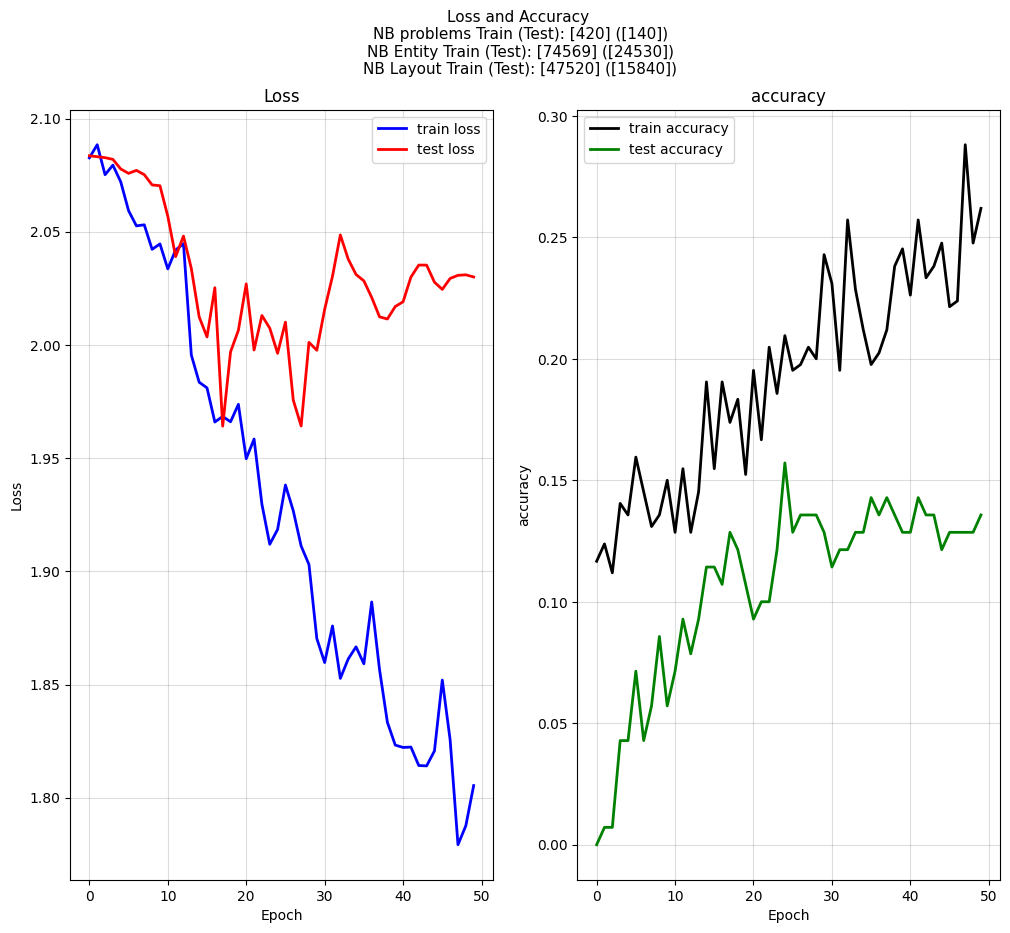

In [9]:
# read json history_dict 
output_path = paths.get_output_path()
train_only=False
# for config in Configuration.all()[:1]:
    # history_dict_path = output_path /"history"/"gnn"/f"training_history_{config}.json"
    # with open(history_dict_path, 'r') as json_file:
    #     history_dict = json.load(json_file)
        # print(history_dict)
cfg_history_dict = history
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12,10))
subtitle = f"Loss and Accuracy \n"
subtitle +=f"NB problems Train (Test): {cfg_history_dict["train_number_of_problems"]} ({cfg_history_dict["test_number_of_problems"]})\n"
subtitle +=f"NB Entity Train (Test): {cfg_history_dict["train_entity"]} ({cfg_history_dict["test_entity"]})\n" 
subtitle +=f"NB Layout Train (Test): {cfg_history_dict["train_layout"]} ({cfg_history_dict["test_layout"]})" 
fig.suptitle(subtitle, fontsize=11)
axes[0].plot(range(epochs), cfg_history_dict['train_loss'] , color='blue', linewidth=2, label='train loss')
if not train_only:
    axes[0].plot(range(epochs), cfg_history_dict['test_loss'] , color='red', linewidth=2, label='test loss')
axes[0].set_title(f'Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.2, color='#555')
axes[1].plot(range(epochs), cfg_history_dict['train_accuracy'],color="black",linewidth=2, label=f'train accuracy')
if not train_only:
    axes[1].plot(range(epochs), cfg_history_dict['test_accuracy'],color="green",linewidth=2, label=f'test accuracy')
axes[1].set_title(f'accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.2, color='#555')
# gnn_curves_path = output_path/"metric_curves"/"gnn"/f"{config}_loss_accuracy.png"
# plt.savefig(gnn_curves_path)
# print(f"\n[OK] {config} curves saved to {gnn_curves_path}")

